# 00 — Python em ação
## Da epidemia ao planejamento em saúde

**Pergunta:** como dados podem orientar vigilância, alocação de equipes e comunicação de risco?

A base desta oficina usa **dados oficiais**: notificações de dengue do SINAN/DATASUS (2024 e 2025), população IBGE e renda domiciliar per capita do Censo 2022 (SIDRA). Os números são agregados por município e semana, com um arquivo por ano para comparar os ciclos anuais.

In [1]:
from pathlib import Path
import sys
ROOT=Path.cwd().parent if Path.cwd().name=="notebooks" else Path.cwd()
sys.path.insert(0,str(ROOT))
# Setting up the environment and loading the necessary data
from scripts.carregar_dados import caminhos, semana_epidemiologica
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_theme(style="whitegrid",palette="colorblind")

# 1. Loading the data files for cases and municipalities
arq_casos, arq_municipios, FONTE = caminhos()
casos={ano:pd.read_csv(p,parse_dates=["semana"],dtype={"codigo_ibge":"string"}) for ano,p in arq_casos.items()}
municipios=pd.read_csv(arq_municipios,dtype={"codigo_ibge":"string"})

# 2. Displaying the selected data source and a preview of the cases data
print("Fonte selecionada:",FONTE,"| anos:",", ".join(casos))
casos["2024"].head()


Fonte selecionada: SINAN/DATASUS + IBGE (dados oficiais agregados) | anos: 2024, 2025


,codigo_ibge,municipio,semana,casos
0,5200050,Abadia de Goiás,2024-01-14,10
1,5200050,Abadia de Goiás,2024-01-21,16
2,5200050,Abadia de Goiás,2024-01-28,6
3,5200050,Abadia de Goiás,2024-02-04,5
4,5200050,Abadia de Goiás,2024-02-11,15


In [2]:
for ano,df in casos.items():
    print(f"{ano}: {len(df):,} linhas | {df.municipio.nunique()} municípios | {df.semana.min().date()} a {df.semana.max().date()} | {df.casos.sum():,} casos")
# 3. Displaying a summary of the cases data by municipality, one column per year
pd.concat({ano:df.groupby("municipio").casos.sum() for ano,df in casos.items()},axis=1).sort_values(list(casos)[0],ascending=False).head(8)

2024: 7,673 linhas | 246 municípios | 2023-12-31 a 2024-12-22 | 334,555 casos
2025: 6,519 linhas | 246 municípios | 2024-12-29 a 2025-12-28 | 105,673 casos


,2024,2025
municipio,,
Goiânia,57890,32816
Anápolis,39050,2123
Aparecida de Goiânia,24933,17732
Luziânia,17109,2155
Novo Gama,11603,596
Rio Verde,10170,4049
Águas Lindas de Goiás,9935,441
Valparaíso de Goiás,8940,1354


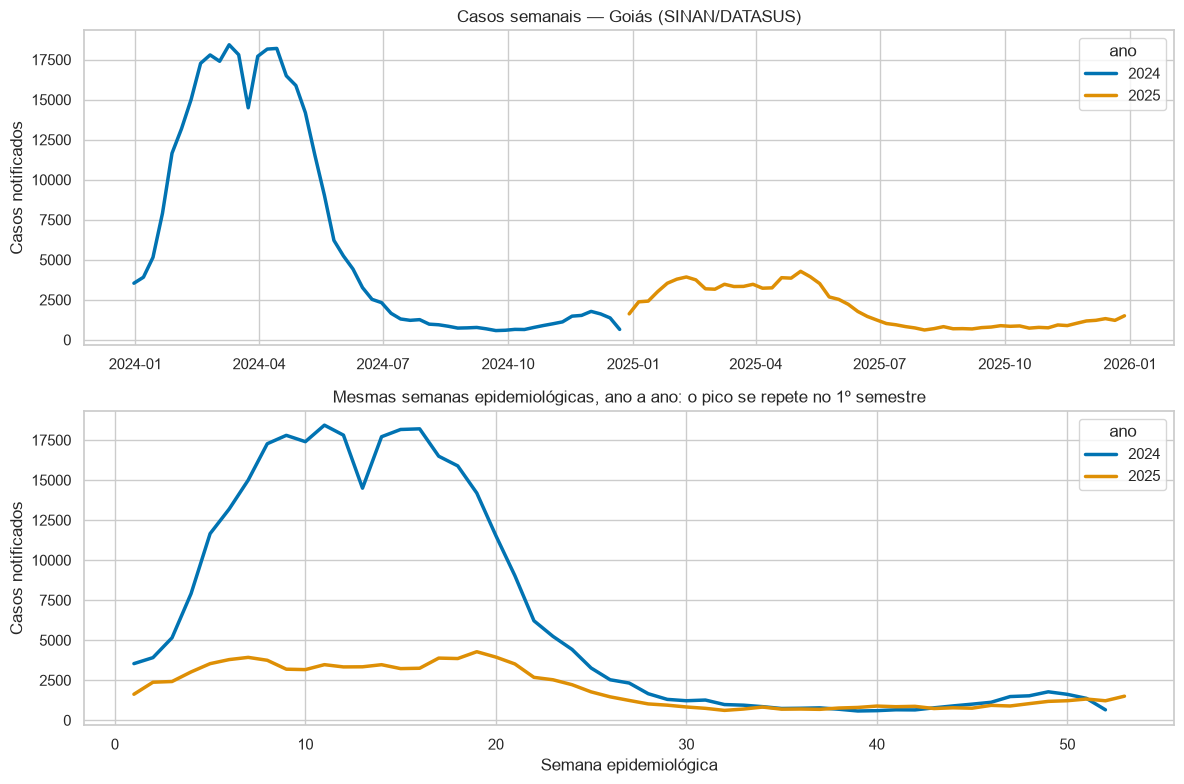

In [3]:
go=pd.concat([df.groupby("semana",as_index=False).casos.sum().assign(ano=ano) for ano,df in casos.items()])
go["semana_epi"]=semana_epidemiologica(go.semana)[1]
# 4. Plotting the weekly cases for Goiás: continuous timeline and years overlaid by epidemiological week
fig,axes=plt.subplots(2,1,figsize=(12,8))
# 4a. Preparing the figure and axes for the plots
sns.lineplot(data=go,x="semana",y="casos",hue="ano",linewidth=2.5,ax=axes[0])
axes[0].set(title="Casos semanais — Goiás (SINAN/DATASUS)",xlabel="",ylabel="Casos notificados")
# 4b. Plotting the weekly cases by epidemiological week
sns.lineplot(data=go,x="semana_epi",y="casos",hue="ano",linewidth=2.5,ax=axes[1])
axes[1].set(title="Mesmas semanas epidemiológicas, ano a ano: o pico se repete no 1º semestre",xlabel="Semana epidemiológica",ylabel="Casos notificados")
plt.tight_layout(); plt.show()

### Para discutir

- Um pico significa necessariamente epidemia?
- O pico de 2025 ocorre nas mesmas semanas epidemiológicas que o de 2024? O que isso sugere sobre sazonalidade?
- Contagens absolutas permitem comparar municípios de tamanhos diferentes?
- Qual decisão de gestão este gráfico pode apoiar — e qual ele não pode?